## 06 - Modelagem em duas etapas: ocorrência e intensidade da precipitação

A avaliação da regressão direta evidenciou dificuldade na estimativa de eventos de precipitação intensa, além da predominância de dias secos ou com baixos acumulados.

Como abordagem complementar, o problema de previsão foi dividido em duas etapas. A primeira etapa consiste em classificar a ocorrência de precipitação no dia seguinte, enquanto a segunda estima o volume de chuva apenas para os dias classificados como chuvosos.

Para manter a consistência com as análises anteriores, foi adotado como evento de chuva o acumulado diário igual ou superior a 1 mm. O desenvolvimento e a seleção dos modelos são realizados utilizando apenas o conjunto de treino, com validação temporal por `TimeSeriesSplit`.

In [2]:
import pandas as pd
import numpy as np

# Carrega a base diária
df = pd.read_parquet(
    "../data/gold/a701_2010_2025_diario.parquet"
)

# Data
df["DATA (YYYY-MM-DD)"] = pd.to_datetime(
    df["DATA (YYYY-MM-DD)"]
)

# Variáveis de calendário
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month
df["dia_ano"] = df["DATA (YYYY-MM-DD)"].dt.dayofyear

df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

df["dia_ano_sin"] = np.sin(
    2 * np.pi * df["dia_ano"] / 365.25
)

df["dia_ano_cos"] = np.cos(
    2 * np.pi * df["dia_ano"] / 365.25
)

# Lags de precipitação
df["precipitacao_lag_1"] = df["precipitacao_diaria_mm"].shift(1)
df["precipitacao_lag_2"] = df["precipitacao_diaria_mm"].shift(2)
df["precipitacao_lag_3"] = df["precipitacao_diaria_mm"].shift(3)

# Médias móveis
df["media_movel_3"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(3)
    .mean()
)

df["media_movel_7"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(7)
    .mean()
)

# Variáveis meteorológicas defasadas
df["temperatura_lag_1"] = df["temperatura_media"].shift(1)
df["umidade_lag_1"] = df["umidade_media"].shift(1)
df["pressao_lag_1"] = df["pressao_media"].shift(1)
df["vento_lag_1"] = df["vento_medio"].shift(1)

# Features multivariadas
features_multivariadas = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7",
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

alvo = "precipitacao_diaria_mm"

# Base de modelagem
base_modelagem = df[
    ["DATA (YYYY-MM-DD)", alvo] + features_multivariadas
].dropna().copy()

# Split cronológico 80/20
indice_corte = int(len(base_modelagem) * 0.8)

treino = base_modelagem.iloc[:indice_corte].copy()
teste = base_modelagem.iloc[indice_corte:].copy()

print("Base:", len(base_modelagem))
print("Treino:", len(treino))
print("Teste:", len(teste))

Base: 4954
Treino: 3963
Teste: 991


In [3]:
treino_duas_etapas = treino.copy()

treino_duas_etapas["choveu"] = (
    treino_duas_etapas["precipitacao_diaria_mm"] >= 1
).astype(int)

treino_duas_etapas[
    ["precipitacao_diaria_mm", "choveu"]
].head(10)

,precipitacao_diaria_mm,choveu
7,30.2,1
8,0.2,0
9,0.6,0
10,29.2,1
11,0.0,0
20,46.0,1
28,10.0,1
29,0.0,0
30,1.0,1
31,34.2,1


In [4]:
distribuicao_chuva = (
    treino_duas_etapas["choveu"]
    .value_counts()
    .sort_index()
)

percentual_chuva = (
    treino_duas_etapas["choveu"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("Quantidade:")
print(distribuicao_chuva)

print("\nPercentual:")
print(percentual_chuva.round(2))

Quantidade:
choveu
0    2725
1    1238
Name: count, dtype: int64

Percentual:
choveu
0    68.76
1    31.24
Name: proportion, dtype: float64


### Etapa 1 - Classificação da ocorrência de chuva

A primeira etapa da abordagem em duas fases consiste em classificar se haverá ou não ocorrência de precipitação no dia seguinte.

Foi considerado como dia chuvoso aquele com precipitação diária igual ou superior a 1 mm. No conjunto de treino, aproximadamente 31% dos registros pertencem à classe de chuva, enquanto cerca de 69% correspondem a dias sem chuva relevante.

O desempenho do classificador será avaliado utilizando validação temporal por `TimeSeriesSplit`.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_class = treino_duas_etapas[features_multivariadas].copy()
y_class = treino_duas_etapas["choveu"].copy()

tscv = TimeSeriesSplit(n_splits=5)

resultados_classificacao = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo_classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo_classificador.fit(X_tr, y_tr)

    y_pred = modelo_classificador.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    resultados_classificacao.append(
        [fold, acc, precision, recall, f1]
    )

    print(
        f"Fold {fold} | "
        f"Accuracy: {acc:.3f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Fold 1 | Accuracy: 0.709 | Precision: 0.548 | Recall: 0.609 | F1: 0.577
Fold 2 | Accuracy: 0.700 | Precision: 0.540 | Recall: 0.619 | F1: 0.577
Fold 3 | Accuracy: 0.718 | Precision: 0.533 | Recall: 0.597 | F1: 0.563
Fold 4 | Accuracy: 0.711 | Precision: 0.527 | Recall: 0.632 | F1: 0.575
Fold 5 | Accuracy: 0.750 | Precision: 0.547 | Recall: 0.574 | F1: 0.560


#### Avaliação inicial da classificação de ocorrência de chuva

A Random Forest utilizada para classificar a ocorrência de precipitação apresentou desempenho relativamente estável ao longo dos cinco folds da validação temporal.

O recall permaneceu próximo de 0,60, indicando que o modelo identificou aproximadamente 60% dos dias em que ocorreu precipitação igual ou superior a 1 mm. A precisão ficou próxima de 0,54, mostrando que parte das previsões de chuva correspondeu a falsos positivos.

O F1-score médio ficou próximo de 0,57, indicando capacidade moderada de discriminação entre dias com e sem ocorrência de chuva.

Os resultados mostram que as variáveis utilizadas possuem informação relevante para identificação da ocorrência de precipitação, embora ainda existam quantidades importantes de falsos negativos e falsos positivos.

### Matriz de confusão da classificação

Para complementar as métricas de classificação, as previsões geradas nos cinco folds da validação temporal foram reunidas para construir uma matriz de confusão global.

Essa análise permite quantificar os acertos e erros do modelo na identificação de dias com e sem precipitação.

[[1748  531]
 [ 401  620]]


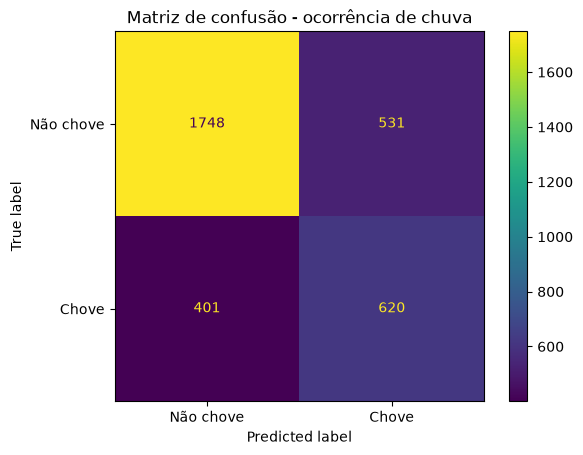

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
y_real_validacao = []
y_pred_validacao = []

for idx_train, idx_val in tscv.split(X_class):

    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo_classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo_classificador.fit(X_tr, y_tr)

    y_pred = modelo_classificador.predict(X_val)

    y_real_validacao.extend(y_val)
    y_pred_validacao.extend(y_pred)

matriz = confusion_matrix(
    y_real_validacao,
    y_pred_validacao
)

print(matriz)

display = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Não chove",
        "Chove"
    ]
)

display.plot()
plt.title("Matriz de confusão - ocorrência de chuva")
plt.show()

#### Interpretação da matriz de confusão

A matriz de confusão, construída a partir das previsões dos cinco folds da validação temporal, apresentou 1.748 verdadeiros negativos, 620 verdadeiros positivos, 531 falsos positivos e 401 falsos negativos.

O classificador identificou aproximadamente **60,7% dos dias com precipitação igual ou superior a 1 mm**, deixando de detectar 39,3% dos eventos observados.

Esse resultado evidencia uma limitação importante para a abordagem em duas etapas, pois os dias chuvosos classificados incorretamente como secos não seriam encaminhados ao modelo de regressão de intensidade.

Dessa forma, torna-se relevante investigar diferentes limiares de decisão, buscando melhorar a identificação dos dias chuvosos sem aumentar excessivamente a quantidade de falsos positivos.

### Avaliação de diferentes limiares de classificação

Após a avaliação inicial do classificador, foram investigados diferentes limiares de decisão (*thresholds*) para a identificação de dias chuvosos.

O objetivo dessa análise é verificar se a redução do limiar padrão de 0,50 permite aumentar a sensibilidade do modelo, reduzindo a quantidade de eventos de chuva não identificados.

As probabilidades de classificação foram obtidas utilizando os mesmos cinco folds da validação temporal, mantendo a separação cronológica entre treinamento e validação. Foram analisadas as métricas precision, recall, F1-score e a quantidade de falsos positivos e falsos negativos para cada limiar.

A escolha do limiar será considerada posteriormente em conjunto com o desempenho da regressão de intensidade, uma vez que um maior recall não garante necessariamente menor erro na previsão do volume de chuva.

In [8]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Armazena os valores reais e as probabilidades
y_real_validacao = []
prob_chuva_validacao = []

# Mesmos 5 folds temporais
for idx_train, idx_val in tscv.split(X_class):

    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo.fit(X_tr, y_tr)

    # Probabilidade estimada para a classe 1 (chuva)
    probabilidades = modelo.predict_proba(X_val)[:, 1]

    y_real_validacao.extend(y_val)
    prob_chuva_validacao.extend(probabilidades)


# Diferentes thresholds para avaliação
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

resultados_thresholds = []

for threshold in thresholds:

    # Converte probabilidade em classificação
    y_pred = (
        np.array(prob_chuva_validacao) >= threshold
    ).astype(int)

    precision = precision_score(y_real_validacao, y_pred)
    recall = recall_score(y_real_validacao, y_pred)
    f1 = f1_score(y_real_validacao, y_pred)

    tn, fp, fn, tp = confusion_matrix(
        y_real_validacao,
        y_pred,
        labels=[0, 1]
    ).ravel()

    resultados_thresholds.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Falsos_positivos": fp,
        "Falsos_negativos": fn
    })

df_thresholds = pd.DataFrame(resultados_thresholds)

df_thresholds.round(3)

,Threshold,Precision,Recall,F1,Falsos_positivos,Falsos_negativos
0,0.30,0.457,0.867,0.598,1053,136
1,0.35,0.478,0.826,0.605,921,178
2,0.40,0.499,0.778,0.608,796,227
3,0.45,0.514,0.702,0.594,677,304
4,0.50,0.536,0.619,0.574,548,389


#### Análise dos limiares de classificação

A avaliação de diferentes limiares de decisão demonstrou que a redução do threshold aumenta a sensibilidade do classificador para identificação de dias chuvosos, embora também eleve a quantidade de falsos positivos.

Entre os limiares avaliados, o valor de **0,40 apresentou o maior F1-score (0,608)**, com precision de **49,9%** e recall de **77,8%**.

Em comparação com o threshold de 0,50, a quantidade de falsos negativos diminuiu de 389 para 227, enquanto os falsos positivos aumentaram de 548 para 796.

Considerando a arquitetura em duas etapas, o threshold de 0,40 foi selecionado como candidato para a avaliação conjunta dos componentes de classificação e regressão. Sua adequação definitiva dependerá do desempenho obtido na estimativa final do volume de precipitação.

### Etapa 2 — Regressão da intensidade da precipitação

Após a avaliação da classificação de ocorrência de chuva, foi implementada a segunda etapa do modelo, destinada à estimativa do volume diário de precipitação.

Nessa abordagem, o regressor é treinado exclusivamente com os registros de treino cuja precipitação observada foi igual ou superior a 1 mm. Dessa forma, busca-se modelar a intensidade dos eventos chuvosos sem a influência direta dos numerosos registros de precipitação nula ou muito baixa.

Durante a validação, as previsões dos dois componentes são combinadas. Quando a probabilidade estimada pelo classificador é inferior ao limiar de 0,40, a precipitação prevista é definida como 0 mm. Caso contrário, utiliza-se a quantidade estimada pelo regressor.

A avaliação é realizada por validação temporal com cinco folds, sem utilização do conjunto de teste final. Os resultados serão comparados às métricas da regressão direta obtidas anteriormente.

In [9]:
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd

threshold = 0.40

resultados_duas_etapas = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    # Dados do fold
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr_class = y_class.iloc[idx_train]

    y_tr_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_train]

    y_val_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    # ETAPA 1 - Classificação
    classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    classificador.fit(X_tr, y_tr_class)

    prob_chuva = classificador.predict_proba(
        X_val
    )[:, 1]

    previsao_chuva = prob_chuva >= threshold

    # ETAPA 2 - Regressão
    # Somente dias realmente chuvosos do treino
    mascara_chuva_treino = y_tr_mm >= 1

    regressor = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )

    regressor.fit(
        X_tr.loc[mascara_chuva_treino],
        y_tr_mm.loc[mascara_chuva_treino]
    )

    # Previsão final das duas etapas
    y_pred = np.zeros(len(X_val))

    if previsao_chuva.any():
        y_pred[previsao_chuva] = regressor.predict(
            X_val.loc[previsao_chuva]
        )

    # Avaliação em todos os dias do fold
    mae = mean_absolute_error(
        y_val_mm,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_mm,
            y_pred
        )
    )

    resultados_duas_etapas.append({
        "Fold": fold,
        "MAE_mm": mae,
        "RMSE_mm": rmse
    })

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

df_resultados_duas_etapas = pd.DataFrame(
    resultados_duas_etapas
)

print("\nMédia dos folds")
print(
    f"MAE médio: "
    f"{df_resultados_duas_etapas['MAE_mm'].mean():.3f} mm"
)
print(
    f"RMSE médio: "
    f"{df_resultados_duas_etapas['RMSE_mm'].mean():.3f} mm"
)

Fold 1 | MAE: 7.264 mm | RMSE: 11.444 mm
Fold 2 | MAE: 7.550 mm | RMSE: 12.087 mm
Fold 3 | MAE: 6.946 mm | RMSE: 11.770 mm
Fold 4 | MAE: 7.405 mm | RMSE: 12.854 mm
Fold 5 | MAE: 5.917 mm | RMSE: 10.609 mm

Média dos folds
MAE médio: 7.016 mm
RMSE médio: 11.753 mm


#### Avaliação inicial da abordagem em duas etapas

A abordagem em duas etapas, composta por um classificador de ocorrência de precipitação e um regressor condicionado aos dias chuvosos, apresentou MAE médio de **7,016 mm** e RMSE médio de **11,753 mm** na validação temporal.

Esses resultados foram inferiores aos obtidos pela Random Forest de regressão direta, que apresentou MAE médio de **5,505 mm** e RMSE médio de **10,459 mm**.

O desempenho inferior pode estar relacionado à propagação dos erros de classificação para a etapa de regressão, especialmente nos casos em que dias chuvosos são classificados como secos ou dias secos são encaminhados ao modelo de intensidade. Além disso, os hiperparâmetros do regressor não foram ajustados especificamente para a nova formulação.

Assim, os resultados iniciais não demonstraram vantagem da arquitetura em duas etapas para a previsão do acumulado diário de precipitação, sendo necessária uma avaliação complementar antes de estabelecer conclusões definitivas.

### Avaliação dos limiares na previsão final de precipitação

Embora o limiar de classificação de 0,40 tenha apresentado o maior F1-score entre os valores inicialmente avaliados, esse resultado não garante o melhor desempenho na estimativa do volume diário de precipitação.

Para investigar essa questão, foram avaliados diferentes limiares de classificação, considerando o desempenho conjunto do classificador de ocorrência e do regressor de intensidade.

A análise foi realizada utilizando os mesmos cinco folds da validação temporal, com as métricas MAE e RMSE calculadas sobre as previsões finais em milímetros.

O objetivo foi identificar se a alteração do limiar de classificação permite reduzir os erros da arquitetura em duas etapas, mantendo o conjunto de teste final fora do processo de seleção.

In [11]:
thresholds = [
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75
]

resultados_thresholds_mm = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    # Dados do fold
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr_class = y_class.iloc[idx_train]

    y_tr_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_train]

    y_val_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    # Etapa 1: classificador
    classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    classificador.fit(X_tr, y_tr_class)

    prob_chuva = classificador.predict_proba(
        X_val
    )[:, 1]

    # Etapa 2: regressor treinado somente em dias chuvosos
    mascara_chuva = y_tr_mm >= 1

    regressor = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )

    regressor.fit(
        X_tr.loc[mascara_chuva],
        y_tr_mm.loc[mascara_chuva]
    )

    # Calcula a intensidade para todos os dias da validação
    intensidade_prevista = np.maximum(
        regressor.predict(X_val),
        0
    )

    # Compara diferentes thresholds
    for threshold in thresholds:

        previsao_chuva = prob_chuva >= threshold

        y_pred_mm = np.where(
            previsao_chuva,
            intensidade_prevista,
            0.0
        )

        mae = mean_absolute_error(
            y_val_mm,
            y_pred_mm
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_mm,
                y_pred_mm
            )
        )

        resultados_thresholds_mm.append({
            "Fold": fold,
            "Threshold": threshold,
            "MAE_mm": mae,
            "RMSE_mm": rmse
        })

# Consolida os resultados dos 5 folds
df_thresholds_mm = pd.DataFrame(
    resultados_thresholds_mm
)

resumo_thresholds_mm = (
    df_thresholds_mm
    .groupby("Threshold")
    .agg(
        MAE_medio_mm=("MAE_mm", "mean"),
        RMSE_medio_mm=("RMSE_mm", "mean")
    )
    .reset_index()
    .sort_values("RMSE_medio_mm")
)

resumo_thresholds_mm.round(3)

,Threshold,MAE_medio_mm,RMSE_medio_mm
3,0.55,5.757,11.459
6,0.70,4.636,11.466
4,0.60,5.362,11.469
2,0.50,6.142,11.499
5,0.65,4.971,11.548
7,0.75,4.439,11.550
1,0.45,6.585,11.583
0,0.40,7.016,11.753


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: prever sempre 0 mm
previsao_zero = np.zeros(len(X_class))

maes_zero = []
rmses_zero = []

for idx_train, idx_val in tscv.split(X_class):

    y_val = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    y_pred = previsao_zero[idx_val]

    mae = mean_absolute_error(y_val, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_val, y_pred)
    )

    maes_zero.append(mae)
    rmses_zero.append(rmse)

print(f"MAE médio - Sempre zero: {np.mean(maes_zero):.3f} mm")
print(f"RMSE médio - Sempre zero: {np.mean(rmses_zero):.3f} mm")

MAE médio - Sempre zero: 4.288 mm
RMSE médio - Sempre zero: 11.776 mm


### Comparação com o baseline de precipitação nula

Para investigar a redução contínua do MAE observada com o aumento do limiar de classificação, foi avaliado um baseline adicional que prevê precipitação igual a zero para todos os dias.

Esse baseline apresentou MAE médio de **4,288 mm** e RMSE médio de **11,776 mm** na validação temporal.

O resultado evidencia que a previsão constante de precipitação nula pode produzir baixo erro absoluto médio em uma série caracterizada pela predominância de dias secos ou com baixos acumulados. Entretanto, essa estratégia não possui capacidade de identificar eventos chuvosos.

A Random Forest de regressão direta apresentou RMSE inferior ao baseline de precipitação nula, indicando maior capacidade de reduzir erros de grande magnitude.

Na abordagem em duas etapas, o aumento do limiar para 0,75 reduziu o MAE para **4,439 mm**, valor próximo ao obtido pela previsão constante de zero, enquanto o RMSE permaneceu relativamente elevado, em **11,550 mm**.

Esses resultados demonstram a necessidade de interpretar as métricas MAE e RMSE conjuntamente, evitando selecionar modelos apenas pela minimização do erro absoluto médio.

### Frequência de previsões de chuva por limiar de classificação

Para investigar o comportamento da arquitetura em duas etapas, foi analisada a proporção de dias classificados como chuvosos e não chuvosos para diferentes limiares de decisão.

Essa análise busca verificar se a redução do MAE observada com o aumento do threshold está associada a uma maior frequência de previsões de precipitação nula.

Foram avaliados os limiares de 0,40, 0,55 e 0,75, utilizando as probabilidades estimadas pelo classificador nos cinco folds da validação temporal.

In [13]:
thresholds_analise = [0.40, 0.55, 0.75]

probabilidades = np.array(prob_chuva_validacao)

resultados_frequencia = []

for threshold in thresholds_analise:

    # Identifica os dias classificados como chuvosos
    previsao_chuva = probabilidades >= threshold

    total_dias = len(previsao_chuva)

    dias_chuva = previsao_chuva.sum()
    dias_sem_chuva = total_dias - dias_chuva

    resultados_frequencia.append({
        "Threshold": threshold,
        "Total_dias": total_dias,
        "Dias_previstos_chuva": dias_chuva,
        "Dias_previstos_sem_chuva": dias_sem_chuva,
        "Percentual_chuva": dias_chuva / total_dias * 100,
        "Percentual_sem_chuva": dias_sem_chuva / total_dias * 100
    })

df_frequencia = pd.DataFrame(resultados_frequencia)

df_frequencia.round(2)

,Threshold,Total_dias,Dias_previstos_chuva,Dias_previstos_sem_chuva,Percentual_chuva,Percentual_sem_chuva
0,0.40,3300,1590,1710,48.18,51.82
1,0.55,3300,960,2340,29.09,70.91
2,0.75,3300,158,3142,4.79,95.21


### Análise da frequência de previsões nulas

A análise da frequência de dias classificados como chuvosos demonstrou que o aumento do limiar de decisão tornou o modelo progressivamente mais conservador.

Com threshold de 0,40, aproximadamente **51,82% dos dias receberam previsão de precipitação nula**. Esse percentual aumentou para **70,91%** com threshold de 0,55 e alcançou **95,21%** com threshold de 0,75.

O resultado explica a redução progressiva do MAE observada nas avaliações anteriores. Ao prever ausência de precipitação com maior frequência, o modelo reduz os erros absolutos em muitos dias secos ou com baixos acumulados, mas também deixa de identificar eventos reais de chuva.

Essa interpretação é reforçada pelo baseline que prevê sempre zero, cujo MAE médio foi de **4,288 mm**, inferior ao obtido pela arquitetura em duas etapas com threshold de 0,75 (**4,439 mm**).

Por outro lado, a Random Forest de regressão direta apresentou RMSE médio de **10,459 mm**, inferior ao da abordagem em duas etapas em todos os limiares avaliados.

Dessa forma, os resultados demonstram que a otimização isolada do MAE pode favorecer estratégias excessivamente conservadoras em séries de precipitação com predominância de valores baixos ou nulos. Para o objetivo de estimar o acumulado diário, a regressão direta permaneceu como a alternativa mais adequada entre as configurações avaliadas, considerando especialmente a redução dos erros de maior magnitude.

## Conclusão da modelagem em duas etapas

Neste experimento, foi investigada uma abordagem alternativa para a previsão da precipitação diária, baseada na separação entre ocorrência e intensidade da chuva. A arquitetura utilizou um classificador Random Forest para identificar dias com precipitação igual ou superior a 1 mm e um regressor Random Forest para estimar o volume de chuva nos dias classificados como chuvosos.

A classificação apresentou desempenho moderado, com recall próximo de 61% na configuração inicial. A avaliação de diferentes limiares demonstrou que o aumento da sensibilidade permitiu identificar uma parcela maior dos eventos chuvosos, mas também elevou a quantidade de falsos positivos.

Na avaliação conjunta das duas etapas, o limiar de 0,55 apresentou o menor RMSE médio entre os valores analisados, com **11,459 mm** e MAE de **5,757 mm**. Por outro lado, o limiar de 0,75 apresentou MAE menor, de **4,439 mm**, mas RMSE de **11,550 mm**.

A análise da frequência de previsões demonstrou que, com limiar de 0,75, aproximadamente **95,21% dos dias foram classificados como sem chuva**. Esse comportamento, associado ao MAE de **4,288 mm** obtido pelo baseline que prevê sempre zero, evidencia que a minimização isolada do erro absoluto médio pode favorecer previsões excessivamente conservadoras.

Em comparação, a Random Forest multivariada de regressão direta apresentou MAE médio de **5,505 mm** e RMSE médio de **10,459 mm** na validação temporal, mantendo desempenho superior em RMSE às configurações avaliadas da arquitetura em duas etapas.

Dessa forma, **a modelagem em duas etapas não demonstrou vantagem consistente sobre a regressão direta para a previsão do acumulado diário de precipitação**, considerando os dados, atributos e configurações empregados.

Os resultados também indicam que a distinção entre ocorrência e intensidade, isoladamente, não foi suficiente para superar as limitações identificadas. Trabalhos futuros poderão investigar o ajuste específico dos modelos de classificação e regressão, outras técnicas de previsão probabilística e a incorporação de informações meteorológicas adicionais.

Conclui-se que, entre as abordagens investigadas, a **Random Forest multivariada de regressão direta permanece como o modelo principal selecionado**, considerando o equilíbrio entre as métricas de validação e o objetivo de prever a quantidade diária de chuva.